# CIFAR-10 Three-Class Classification (airplane / automobile / ship)

A small CNN trained **from scratch** in PyTorch on a 3-class subset of CIFAR-10 (32×32 RGB images).
Two experiments are compared, identical in every respect except one factor.

In [2]:
import json
import math
import os
import platform
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from torch.utils.data import DataLoader, TensorDataset

## 1. Reproducibility & parameters

Every setting that can influence a result is defined in the next cell and **nowhere else**. Change values there only.
The same seed (42) drives the train/validation split, the initial weights, the batch order and the augmentation randomness,
so re-running the notebook reproduces the same numbers on the same machine and software versions
(different hardware or PyTorch versions can still cause tiny floating-point differences).
The parameters and environment are saved to `results/run_config.json`.

In [ ]:
# --- Reproducibility ---
SEED = 42                  # drives: split, weight init, batch order, augmentation
DETERMINISTIC = True       # request deterministic PyTorch kernels (may be a bit slower on GPU)

# --- Data ---
CLASS_NAMES = ["airplane", "automobile", "ship"]   # label order from labels.txt (0, 1, 2)
VAL_DIVISOR = 5            # reserve 1/5 of each class for validation (integer division = rounded down)

# --- Training (identical in every experiment) ---
EPOCHS = 5                 # brief: 5 epochs, optionally 10
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01        # AdamW default

# --- The only factor that differs between experiments ---
FLIP_PROB = 0.5            # probability of flipping a training image horizontally (experiment B)

# --- Reporting ---
N_MISCLASSIFIED = 12       # misclassified test images shown per model (>= 6 required; all if fewer)

# --- Optional robustness check: repeat A and B with other seeds (off by default) ---
RUN_EXTRA_SEEDS = False
EXTRA_SEEDS = [1, 2, 3, 4]

# --- Paths (this notebook lives in <root>/notebook/) ---
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebook" else CWD
DATA_DIR = ROOT / "DataSet"
IMG_DIR = ROOT / "img"
MODEL_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
for d in (IMG_DIR, MODEL_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
if not (DATA_DIR / "dataset.npz").exists():
    raise FileNotFoundError(f"dataset.npz not found in {DATA_DIR}. Run from <root>/notebook/ or <root>/.")

# --- Seeding & determinism ---
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8") 


def set_seed(seed):
    # Seed every random number generator used in this notebook.
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
if DETERMINISTIC:
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

# --- Record parameters + environment ---
RUN_CONFIG = {
    "parameters": {
        "SEED": SEED, "DETERMINISTIC": DETERMINISTIC, "CLASS_NAMES": CLASS_NAMES, "VAL_DIVISOR": VAL_DIVISOR,
        "EPOCHS": EPOCHS, "BATCH_SIZE": BATCH_SIZE, "LEARNING_RATE": LEARNING_RATE, "WEIGHT_DECAY": WEIGHT_DECAY,
        "OPTIMIZER": "AdamW", "LOSS": "CrossEntropyLoss (raw logits)", "FLIP_PROB": FLIP_PROB,
        "N_MISCLASSIFIED": N_MISCLASSIFIED, "RUN_EXTRA_SEEDS": RUN_EXTRA_SEEDS, "EXTRA_SEEDS": EXTRA_SEEDS,
    },
    "environment": {
        "python": sys.version.split()[0], "platform": platform.platform(),
        "numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__,
        "device": str(DEVICE), "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    },
}
(RESULTS_DIR / "run_config.json").write_text(json.dumps(RUN_CONFIG, indent=2), encoding="utf-8")
#print(json.dumps(RUN_CONFIG, indent=2))
#print("\nroot:", ROOT)

{
  "parameters": {
    "SEED": 42,
    "DETERMINISTIC": true,
    "CLASS_NAMES": [
      "airplane",
      "automobile",
      "ship"
    ],
    "VAL_DIVISOR": 5,
    "EPOCHS": 5,
    "BATCH_SIZE": 64,
    "LEARNING_RATE": 0.001,
    "WEIGHT_DECAY": 0.01,
    "OPTIMIZER": "AdamW",
    "LOSS": "CrossEntropyLoss (raw logits)",
    "FLIP_PROB": 0.5,
    "N_MISCLASSIFIED": 12,
    "RUN_EXTRA_SEEDS": false,
    "EXTRA_SEEDS": [
      1,
      2,
      3,
      4
    ]
  },
  "environment": {
    "python": "3.13.9",
    "platform": "Windows-11-10.0.26300-SP0",
    "numpy": "2.4.2",
    "pandas": "2.2.3",
    "torch": "2.12.1+cpu",
    "device": "cpu",
    "cuda": null,
    "gpu": null
  }
}

root: c:\intro-ai\Midterm_Project_Topic\CIFAR10_Three_Class_Vehicle_Classification


## 2. Data: loading, checks and train/validation split

In [4]:
data = np.load(DATA_DIR / "dataset.npz")
x_train_all, y_train_all = data["x_train"], data["y_train"]      # training pool (N, 3, 32, 32) uint8
x_test_raw, y_test_raw = data["x_test"], data["y_test"]          # test set, kept separate until the end
K = len(CLASS_NAMES)


def check_arrays(name, x, y):
    counts = {CLASS_NAMES[c]: int((y == c).sum()) for c in range(K)}
    print(f"{name:<5} images {x.shape} {x.dtype} | labels {y.shape} {y.dtype} | "
          f"pixel range {x.min()}-{x.max()} | per-class {counts}")
    assert x.ndim == 4 and x.shape[1:] == (3, 32, 32) and x.dtype == np.uint8
    assert set(np.unique(y)) == set(range(K))


check_arrays("train", x_train_all, y_train_all)
check_arrays("test", x_test_raw, y_test_raw)

# labels.txt must agree with CLASS_NAMES
labels_txt = {}
for line in (DATA_DIR / "labels.txt").read_text(encoding="utf-8").splitlines():
    if line.strip():
        key, value = line.split(":")
        labels_txt[int(key)] = value.strip()
assert [labels_txt[i] for i in range(len(labels_txt))] == CLASS_NAMES, "labels.txt does not match CLASS_NAMES"

train images (15000, 3, 32, 32) uint8 | labels (15000,) int64 | pixel range 0-255 | per-class {'airplane': 5000, 'automobile': 5000, 'ship': 5000}
test  images (3000, 3, 32, 32) uint8 | labels (3000,) int64 | pixel range 0-255 | per-class {'airplane': 1000, 'automobile': 1000, 'ship': 1000}


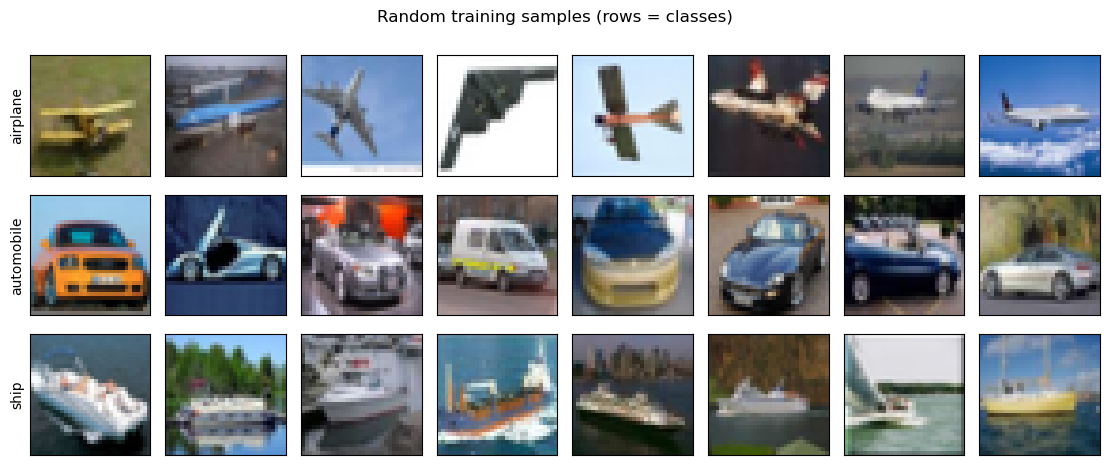

In [5]:
def to_hwc(img_chw):
    # (3, H, W) -> (H, W, 3) for matplotlib
    return np.transpose(img_chw, (1, 2, 0))


n_show = 8
rng_show = np.random.RandomState(SEED)
fig, axes = plt.subplots(K, n_show, figsize=(n_show * 1.4, K * 1.6))
for c, cname in enumerate(CLASS_NAMES):
    for j, i in enumerate(rng_show.choice(np.where(y_train_all == c)[0], n_show, replace=False)):
        axes[c, j].imshow(to_hwc(x_train_all[i]))
        axes[c, j].set_xticks([]); axes[c, j].set_yticks([])
    axes[c, 0].set_ylabel(cname, fontsize=10)
fig.suptitle("Random training samples (rows = classes)")
fig.tight_layout()
fig.savefig(IMG_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
def stratified_split(y, val_divisor, seed):
    # Per class: shuffle, put 1/val_divisor (rounded down) in validation, the rest in training.
    rng = np.random.RandomState(seed)
    train_parts, val_parts = [], []
    for c in range(K):
        idx = rng.permutation(np.where(y == c)[0])
        n_val = len(idx) // val_divisor
        val_parts.append(idx[:n_val])
        train_parts.append(idx[n_val:])
    return rng.permutation(np.concatenate(train_parts)), rng.permutation(np.concatenate(val_parts))


train_idx, val_idx = stratified_split(y_train_all, VAL_DIVISOR, SEED)
np.savez(RESULTS_DIR / "split_indices.npz", train_idx=train_idx, val_idx=val_idx, seed=SEED)

assert set(train_idx).isdisjoint(set(val_idx))
for name, idx in (("train", train_idx), ("validation", val_idx)):
    print(f"{name:<10} {len(idx):>6} images | per class:",
          {CLASS_NAMES[c]: int((y_train_all[idx] == c).sum()) for c in range(K)})

# compare with the numbers announced in dataset_info.json
info = json.loads((DATA_DIR / "dataset_info.json").read_text(encoding="utf-8"))
if VAL_DIVISOR == 5:
    assert len(train_idx) == info["suggested_training"] and len(val_idx) == info["suggested_validation"]
    print("split sizes match dataset_info.json")


def to_tensor(x_uint8):
    # uint8 [0, 255] -> float32 [0, 1]; labels are never scaled
    return torch.from_numpy(x_uint8.astype(np.float32) / 255.0)


X_train, y_train = to_tensor(x_train_all[train_idx]), torch.from_numpy(y_train_all[train_idx]).long()
X_val, y_val = to_tensor(x_train_all[val_idx]), torch.from_numpy(y_train_all[val_idx]).long()
X_test, y_test = to_tensor(x_test_raw), torch.from_numpy(y_test_raw).long()
print(f"\nX_train {tuple(X_train.shape)} | X_val {tuple(X_val.shape)} | X_test {tuple(X_test.shape)} | "
      f"{X_train.dtype}, range [{X_train.min():.1f}, {X_train.max():.1f}]")

train       12000 images | per class: {'airplane': 4000, 'automobile': 4000, 'ship': 4000}
validation   3000 images | per class: {'airplane': 1000, 'automobile': 1000, 'ship': 1000}
split sizes match dataset_info.json

X_train (12000, 3, 32, 32) | X_val (3000, 3, 32, 32) | X_test (3000, 3, 32, 32) | torch.float32, range [0.0, 1.0]


## 3. Model

Baseline from the brief: two convolutional blocks (16 and 32 channels, 3×3 kernels, `padding=1`, ReLU, 2×2 max-pooling),
then `Flatten → Linear(64) → ReLU → Linear(3)`. The network returns raw logits, which are passed directly to `CrossEntropyLoss` (no Softmax).

In [7]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32x32 -> 16x16
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16x16 -> 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# shapes for one batch
set_seed(SEED)
demo_model = SmallCNN(K).to(DEVICE)
xb, yb = next(iter(DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False)))
print(f"input batch : {tuple(xb.shape)} {xb.dtype} | labels {tuple(yb.shape)} {yb.dtype}")
with torch.no_grad():
    h = xb.to(DEVICE)
    for layer in list(demo_model.features) + list(demo_model.classifier):
        h = layer(h)
        print(f"  {layer.__class__.__name__:<10} -> {tuple(h.shape)}")
print(f"output logits: {tuple(h.shape)}  (batch, classes)")
print("trainable parameters:", sum(p.numel() for p in demo_model.parameters() if p.requires_grad))
del demo_model, xb, yb, h

input batch : (64, 3, 32, 32) torch.float32 | labels (64,) torch.int64
  Conv2d     -> (64, 16, 32, 32)
  ReLU       -> (64, 16, 32, 32)
  MaxPool2d  -> (64, 16, 16, 16)
  Conv2d     -> (64, 32, 16, 16)
  ReLU       -> (64, 32, 16, 16)
  MaxPool2d  -> (64, 32, 8, 8)
  Flatten    -> (64, 2048)
  Linear     -> (64, 64)
  ReLU       -> (64, 64)
  Linear     -> (64, 3)
output logits: (64, 3)  (batch, classes)
trainable parameters: 136419


## 4. Training

One function trains both experiments, so the only difference is the `augment` flag. Before each run `set_seed(seed)` is called, which gives
**identical initial weights** and **identical batch order**; the flip randomness uses its own generator, so it does not disturb the batch order.
Augmentation is applied to training batches only. Validation and test images are never altered.
The weights with the best validation accuracy (ties broken by lower validation loss) are saved to `models/`.
The reported training loss/accuracy are averages over the epoch's mini-batches (computed while the weights are updating).

In [8]:
def make_loader(X, y, shuffle=False, seed=None):
    generator = None
    if shuffle:
        generator = torch.Generator()
        generator.manual_seed(seed)
    return DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=generator, num_workers=0)


def random_hflip(xb, generator, p):
    # Flip each image of the batch left-right with probability p.
    mask = (torch.rand(xb.size(0), generator=generator) < p).view(-1, 1, 1, 1).to(xb.device)
    return torch.where(mask, xb.flip(-1), xb)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    preds, trues = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * xb.size(0)
        pred = logits.argmax(dim=1)
        correct += (pred == yb).sum().item()
        n += xb.size(0)
        preds.append(pred.cpu())
        trues.append(yb.cpu())
    return total_loss / n, correct / n, torch.cat(preds).numpy(), torch.cat(trues).numpy()


def train_experiment(tag, augment, seed=SEED, out_dir=RESULTS_DIR, verbose=True):
    set_seed(seed)                                    # same seed -> same initial weights for A and B
    model = SmallCNN(K).to(DEVICE)
    fingerprint = sum(p.detach().double().sum().item() for p in model.parameters())
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    train_loader = make_loader(X_train, y_train, shuffle=True, seed=seed)
    val_loader = make_loader(X_val, y_val)
    flip_generator = torch.Generator()
    flip_generator.manual_seed(seed + 1)

    ckpt = MODEL_DIR / f"{tag}_best.pt"
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    best = {"val_acc": -1.0, "val_loss": float("inf"), "epoch": 0}
    history, log = [], [f"Experiment {tag} | augment={augment} | seed={seed} | device={DEVICE} | "
                        f"epochs={EPOCHS} batch={BATCH_SIZE} lr={LEARNING_RATE} weight_decay={WEIGHT_DECAY}",
                        f"initial-weights fingerprint: {fingerprint:.6f}"]
    t_start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        t0 = time.perf_counter()
        model.train()
        run_loss, run_correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment:
                xb = random_hflip(xb, flip_generator, FLIP_PROB)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * xb.size(0)
            run_correct += (logits.argmax(dim=1) == yb).sum().item()
            n += xb.size(0)
        train_loss, train_acc = run_loss / n, run_correct / n
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
        epoch_time = time.perf_counter() - t0

        improved = val_acc > best["val_acc"] or (val_acc == best["val_acc"] and val_loss < best["val_loss"])
        if improved:
            best = {"val_acc": val_acc, "val_loss": val_loss, "epoch": epoch}
            torch.save(model.state_dict(), ckpt)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc, "time_s": epoch_time})
        log.append(f"epoch {epoch:>2}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
                   f"val loss {val_loss:.4f} acc {val_acc:.4f} | {epoch_time:.1f}s" + ("  <- best" if improved else ""))
        if verbose:
            print(log[-1])

    total_time = time.perf_counter() - t_start
    log.append(f"best epoch {best['epoch']} (val acc {best['val_acc']:.4f}) | total training time {total_time:.1f}s")
    if verbose:
        print(log[-1])
    history = pd.DataFrame(history)
    history.to_csv(out_dir / f"{tag}_log.csv", index=False)
    (out_dir / f"{tag}_log.txt").write_text("\n".join(log), encoding="utf-8")
    return {"tag": tag, "augment": augment, "seed": seed, "history": history, "best_epoch": best["epoch"],
            "best_val_acc": best["val_acc"], "best_val_loss": best["val_loss"], "total_time": total_time,
            "ckpt": ckpt, "fingerprint": fingerprint}


A, B = "A_no_augmentation", "B_hflip"
LABELS = {A: "A: no augmentation", B: "B: random h-flip"}

### Experiment A: no augmentation

In [9]:
exp_A = train_experiment(A, augment=False)

epoch  1/5 | train loss 0.8312 acc 0.6195 | val loss 0.6699 acc 0.7137 | 3.2s  <- best
epoch  2/5 | train loss 0.6343 acc 0.7357 | val loss 0.5975 acc 0.7507 | 3.6s  <- best
epoch  3/5 | train loss 0.5495 acc 0.7761 | val loss 0.5179 acc 0.7920 | 4.2s  <- best
epoch  4/5 | train loss 0.4956 acc 0.8019 | val loss 0.5156 acc 0.7840 | 3.8s
epoch  5/5 | train loss 0.4481 acc 0.8223 | val loss 0.4449 acc 0.8217 | 4.1s  <- best
best epoch 5 (val acc 0.8217) | total training time 19.0s


### Experiment B: random horizontal flip (training set only)

In [10]:
exp_B = train_experiment(B, augment=True)
experiments = {A: exp_A, B: exp_B}
print("\nsame initial weights in A and B:", math.isclose(exp_A["fingerprint"], exp_B["fingerprint"], rel_tol=0, abs_tol=1e-9))

epoch  1/5 | train loss 0.8020 acc 0.6402 | val loss 0.6484 acc 0.7243 | 3.4s  <- best
epoch  2/5 | train loss 0.6245 acc 0.7321 | val loss 0.5876 acc 0.7597 | 4.8s  <- best
epoch  3/5 | train loss 0.5446 acc 0.7798 | val loss 0.5162 acc 0.7943 | 3.1s  <- best
epoch  4/5 | train loss 0.4940 acc 0.8002 | val loss 0.4628 acc 0.8177 | 3.4s  <- best
epoch  5/5 | train loss 0.4468 acc 0.8223 | val loss 0.4334 acc 0.8287 | 3.4s  <- best
best epoch 5 (val acc 0.8287) | total training time 18.1s

same initial weights in A and B: True


### Accuracy and loss curves

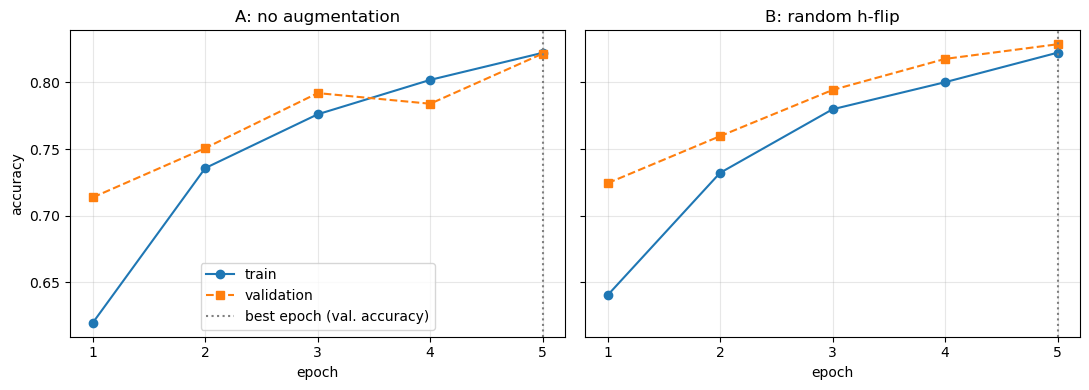

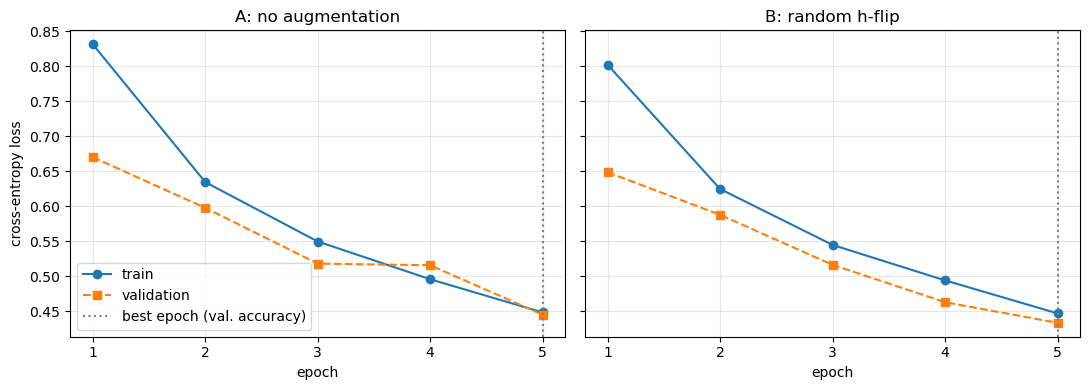

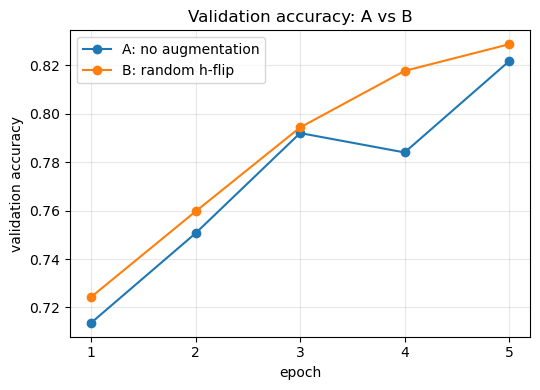

In [11]:
def plot_curves(metric, ylabel, filename):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, (tag, exp) in zip(axes, experiments.items()):
        h = exp["history"]
        ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", label="train")
        ax.plot(h["epoch"], h[f"val_{metric}"], marker="s", linestyle="--", label="validation")
        ax.axvline(exp["best_epoch"], color="grey", linestyle=":", label="best epoch (val. accuracy)")
        ax.set_title(LABELS[tag]); ax.set_xlabel("epoch"); ax.set_xticks(h["epoch"]); ax.grid(alpha=0.3)
    axes[0].set_ylabel(ylabel)
    axes[0].legend()
    fig.tight_layout()
    fig.savefig(IMG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_curves("acc", "accuracy", "accuracy_curves.png")
plot_curves("loss", "cross-entropy loss", "loss_curves.png")

# direct comparison of validation accuracy
fig, ax = plt.subplots(figsize=(5.5, 4))
for tag, exp in experiments.items():
    ax.plot(exp["history"]["epoch"], exp["history"]["val_acc"], marker="o", label=LABELS[tag])
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.set_title("Validation accuracy: A vs B")
ax.set_xticks(exp_A["history"]["epoch"]); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(IMG_DIR / "validation_accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Test evaluation

Each model's **best-validation weights** are loaded and evaluated on the test set **once**. The test set was not used for training, tuning or model selection.
Confusion matrices have **true classes as rows** and **predicted classes as columns**; per-class accuracy = correct predictions of that class ÷ its total sample count.

In [12]:
def load_best(ckpt):
    model = SmallCNN(K).to(DEVICE)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def confusion_matrix(true, pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (true, pred), 1)
    return cm


test_loader = make_loader(X_test, y_test)
criterion = nn.CrossEntropyLoss()
test_results = {}
for tag, exp in experiments.items():
    loss, acc, pred, true = evaluate(load_best(exp["ckpt"]), test_loader, criterion)   # the one and only test evaluation
    assert (true == y_test_raw).all()
    cm = confusion_matrix(true, pred, K)
    test_results[tag] = {"loss": loss, "acc": acc, "pred": pred, "cm": cm, "per_class_acc": np.diag(cm) / cm.sum(axis=1)}
    pd.DataFrame(cm, index=[f"true_{c}" for c in CLASS_NAMES], columns=[f"pred_{c}" for c in CLASS_NAMES]) \
        .to_csv(RESULTS_DIR / f"confusion_matrix_{tag}.csv")

comparison = pd.DataFrame([{
    "experiment": LABELS[t], "best_epoch": experiments[t]["best_epoch"],
    "best_val_acc": experiments[t]["best_val_acc"], "val_loss_at_best": experiments[t]["best_val_loss"],
    "test_acc": r["acc"], "test_loss": r["loss"], "train_time_s": experiments[t]["total_time"],
} for t, r in test_results.items()]).set_index("experiment")
comparison.to_csv(RESULTS_DIR / "comparison.csv")

per_class = pd.DataFrame({LABELS[t]: r["per_class_acc"] for t, r in test_results.items()}, index=CLASS_NAMES)
per_class["B - A (pp)"] = 100 * (per_class[LABELS[B]] - per_class[LABELS[A]])
per_class.index.name = "class"
per_class.to_csv(RESULTS_DIR / "per_class_accuracy.csv")

(RESULTS_DIR / "test_metrics.json").write_text(json.dumps({
    t: {"test_acc": r["acc"], "test_loss": r["loss"],
        "per_class_acc": dict(zip(CLASS_NAMES, map(float, r["per_class_acc"]))), "confusion_matrix": r["cm"].tolist()}
    for t, r in test_results.items()}, indent=2), encoding="utf-8")

print("Overall results"); display(comparison)
print("Per-class test accuracy"); display(per_class)

Overall results


,best_epoch,best_val_acc,val_loss_at_best,test_acc,test_loss,train_time_s
experiment,,,,,,
A: no augmentation,5,0.8217,0.4449,0.8263,0.4459,18.9823
B: random h-flip,5,0.8287,0.4334,0.8320,0.4369,18.1075


Per-class test accuracy


,A: no augmentation,B: random h-flip,B - A (pp)
class,,,
airplane,0.858,0.872,1.4
automobile,0.912,0.897,-1.5
ship,0.709,0.727,1.8


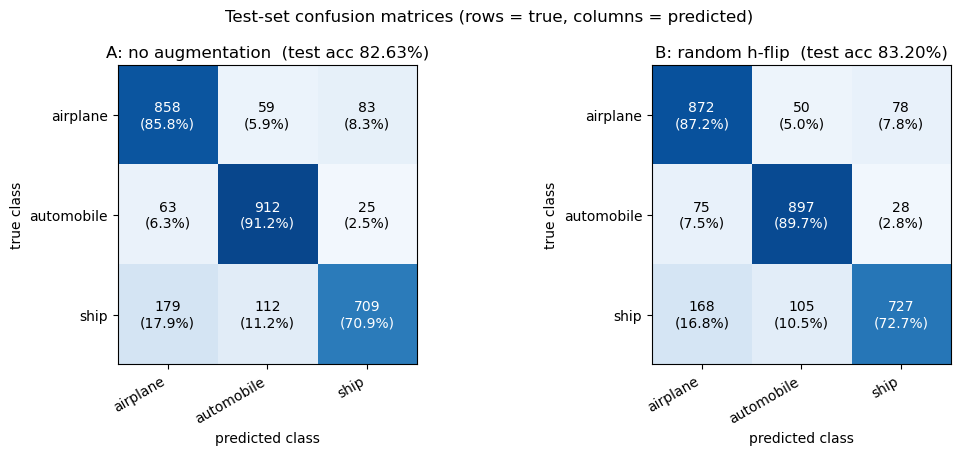

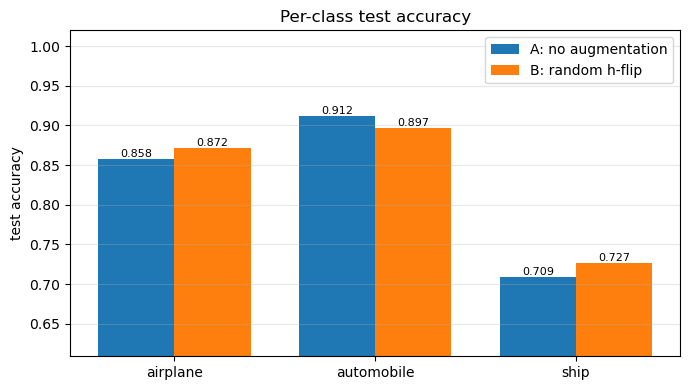

In [13]:
def plot_confusion(ax, cm, title):
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title(title)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]}\n({row_pct[i, j]:.1%})", ha="center", va="center",
                    color="white" if row_pct[i, j] > 0.5 else "black")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (tag, r) in zip(axes, test_results.items()):
    plot_confusion(ax, r["cm"], f"{LABELS[tag]}  (test acc {r['acc']:.2%})")
fig.suptitle("Test-set confusion matrices (rows = true, columns = predicted)")
fig.tight_layout()
fig.savefig(IMG_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

for tag, r in test_results.items():                   # one file per model as well
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    plot_confusion(ax, r["cm"], LABELS[tag])
    fig.tight_layout()
    fig.savefig(IMG_DIR / f"confusion_matrix_{tag}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

# per-class accuracy, A vs B
fig, ax = plt.subplots(figsize=(7, 4))
width = 0.38
for k, (tag, r) in enumerate(test_results.items()):
    bars = ax.bar(np.arange(K) + (k - 0.5) * width, r["per_class_acc"], width, label=LABELS[tag])
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES)
lowest = min(r["per_class_acc"].min() for r in test_results.values())
ax.set_ylim(max(0.0, lowest - 0.1), 1.02)
ax.set_ylabel("test accuracy"); ax.set_title("Per-class test accuracy"); ax.grid(axis="y", alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(IMG_DIR / "per_class_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Error analysis

### Misclassified test images
At least 6 images per model are shown (`N_MISCLASSIFIED`); if there are fewer errors, all of them are shown and the actual count is printed.
The complete list of errors is saved to `results/misclassified_<experiment>.csv`.

A: no augmentation: 521 misclassified test images out of 3000


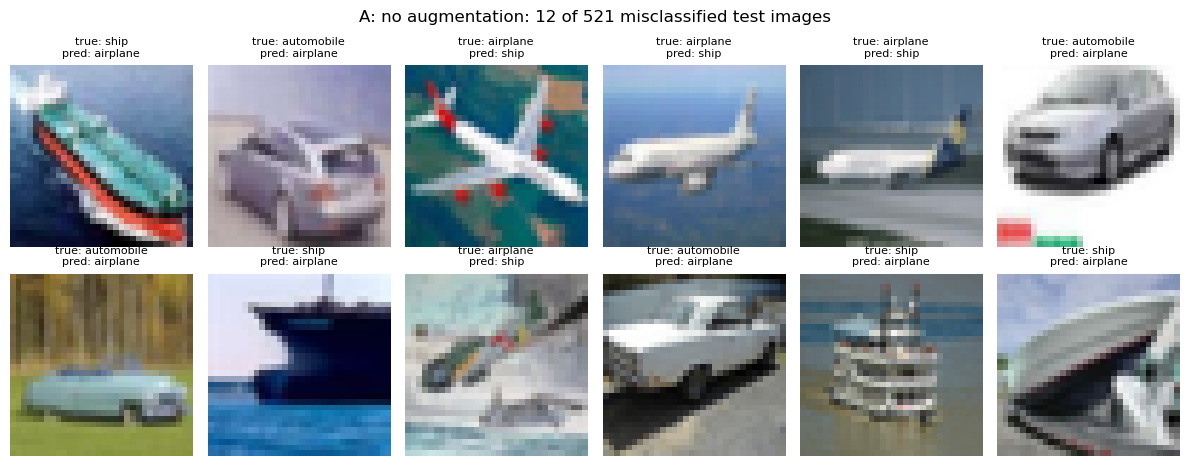

B: random h-flip: 504 misclassified test images out of 3000


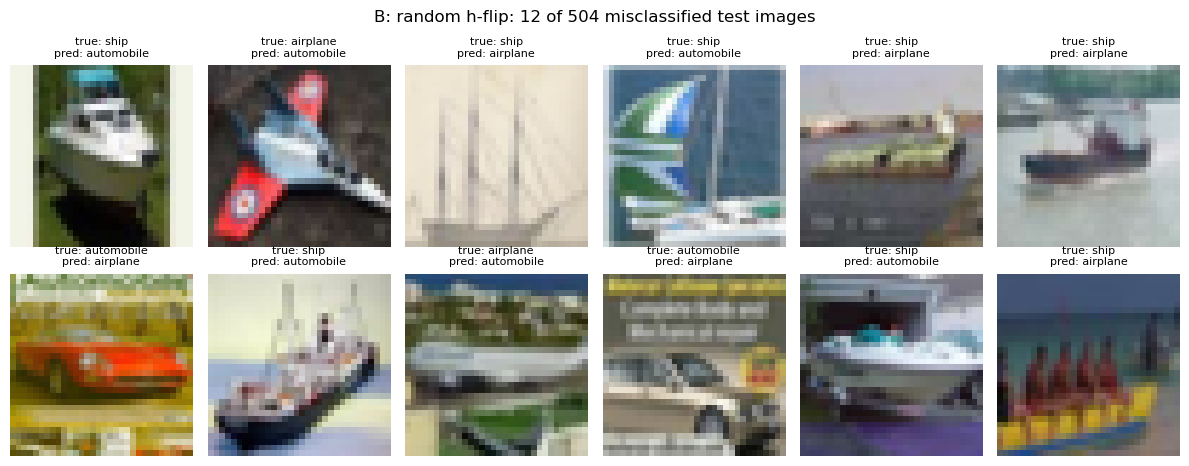

In [14]:
def show_misclassified(tag, pred, n_show):
    wrong = np.where(pred != y_test_raw)[0]
    print(f"{LABELS[tag]}: {len(wrong)} misclassified test images out of {len(y_test_raw)}")
    pd.DataFrame({"test_index": wrong,
                  "true": [CLASS_NAMES[i] for i in y_test_raw[wrong]],
                  "predicted": [CLASS_NAMES[i] for i in pred[wrong]]}).to_csv(RESULTS_DIR / f"misclassified_{tag}.csv", index=False)
    if len(wrong) == 0:
        return
    k = min(n_show, len(wrong))
    chosen = np.sort(np.random.RandomState(SEED).choice(wrong, k, replace=False))
    cols = min(6, k)
    rows = int(np.ceil(k / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.0, rows * 2.4), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), chosen):
        ax.imshow(to_hwc(x_test_raw[i]))
        ax.set_title(f"true: {CLASS_NAMES[y_test_raw[i]]}\npred: {CLASS_NAMES[pred[i]]}", fontsize=8)
    fig.suptitle(f"{LABELS[tag]}: {k} of {len(wrong)} misclassified test images" + (" (all)" if k == len(wrong) else ""))
    fig.tight_layout()
    fig.savefig(IMG_DIR / f"misclassified_{tag}.png", dpi=150, bbox_inches="tight")
    plt.show()


for tag, r in test_results.items():
    show_misclassified(tag, r["pred"], N_MISCLASSIFIED)

### Background colour and errors
To quantify the "coloured background" effect, the **border of each image** (outer 4 pixels, mostly background such as sky, water or road) is summarised by its mean RGB colour.
`blue_excess = B - (R + G) / 2` is large for blue sky / blue water and small or negative for grey, green or brown surroundings.
The table compares correctly classified with misclassified test images, per class and model.

In [15]:
def border_mean_rgb(x_uint8, width=4):
    # Mean R, G, B over the outer `width`-pixel frame of each image -> (N, 3)
    mask = np.ones(x_uint8.shape[2:], dtype=bool)
    mask[width:-width, width:-width] = False
    return x_uint8[:, :, mask].mean(axis=2)


def blue_excess(rgb):
    return rgb[..., 2] - rgb[..., :2].mean(axis=-1)


border = border_mean_rgb(x_test_raw)
rows = []
for c, cname in enumerate(CLASS_NAMES):                                    # reference: all test images of the class
    m = border[y_test_raw == c].mean(axis=0)
    rows.append({"model": "(all images)", "class": cname, "outcome": "all", "n": int((y_test_raw == c).sum()),
                 "border_R": m[0], "border_G": m[1], "border_B": m[2], "blue_excess": blue_excess(m)})
for tag, r in test_results.items():
    for c, cname in enumerate(CLASS_NAMES):
        for outcome, sel in (("correct", (y_test_raw == c) & (r["pred"] == c)),
                             ("misclassified", (y_test_raw == c) & (r["pred"] != c))):
            if sel.sum() == 0:
                continue
            m = border[sel].mean(axis=0)
            rows.append({"model": LABELS[tag], "class": cname, "outcome": outcome, "n": int(sel.sum()),
                         "border_R": m[0], "border_G": m[1], "border_B": m[2], "blue_excess": blue_excess(m)})
background_stats = pd.DataFrame(rows)
background_stats.to_csv(RESULTS_DIR / "background_color_stats.csv", index=False)
display(background_stats.round(1))

# the most frequent error of each model, in terms of background colour
def group_mean(sel):
    return float(blue_excess(border[sel]).mean()) if sel.sum() else float("nan")


for tag, r in test_results.items():
    off = r["cm"].copy()
    np.fill_diagonal(off, 0)
    t, p = np.unravel_index(off.argmax(), off.shape)
    if off[t, p] == 0:
        continue
    print(f"{LABELS[tag]}: most frequent error = true {CLASS_NAMES[t]} -> predicted {CLASS_NAMES[p]} ({off[t, p]} images)\n"
          f"   mean border blue_excess: those errors {group_mean((y_test_raw == t) & (r['pred'] == p)):+.1f} | "
          f"correct {CLASS_NAMES[t]} {group_mean((y_test_raw == t) & (r['pred'] == t)):+.1f} | "
          f"all {CLASS_NAMES[p]} {group_mean(y_test_raw == p):+.1f}")

,model,class,outcome,n,border_R,border_G,border_B,blue_excess
0,(all images),airplane,all,1000,140.5,152.1,162.1,15.8
1,(all images),automobile,all,1000,124.5,122.3,118.7,-4.7
2,(all images),ship,all,1000,122.2,134.0,143.8,15.7
3,A: no augmentation,airplane,correct,858,144.7,156.4,167.0,16.5
4,A: no augmentation,airplane,misclassified,142,115.7,126.3,132.3,11.4
5,A: no augmentation,automobile,correct,912,124.3,122.0,118.2,-4.9
6,A: no augmentation,automobile,misclassified,88,126.2,125.3,123.3,-2.4
7,A: no augmentation,ship,correct,709,119.2,133.2,145.1,18.9
8,A: no augmentation,ship,misclassified,291,129.4,136.0,140.7,8.0
9,B: random h-flip,airplane,correct,872,144.6,156.2,166.6,16.2


A: no augmentation: most frequent error = true ship -> predicted airplane (179 images)
   mean border blue_excess: those errors +13.1 | correct ship +18.9 | all airplane +15.8
B: random h-flip: most frequent error = true ship -> predicted airplane (168 images)
   mean border blue_excess: those errors +11.4 | correct ship +18.9 | all airplane +15.8


## 7. Summary of results (generated from the numbers above)

The paired comparison uses **McNemar's test** (continuity-corrected χ²) on the same 3,000 test images: it only looks at images where the two models disagree,
and asks whether one model wins more of those than chance would explain.

In [16]:
resA, resB, expA, expB = test_results[A], test_results[B], experiments[A], experiments[B]

okA, okB = resA["pred"] == y_test_raw, resB["pred"] == y_test_raw
only_A, only_B = int((okA & ~okB).sum()), int((~okA & okB).sum())
if only_A + only_B > 0:
    chi2 = max(abs(only_A - only_B) - 1, 0) ** 2 / (only_A + only_B)
    p_value = math.erfc(math.sqrt(chi2 / 2))
else:
    p_value = 1.0


def gap_at_best(exp):
    h = exp["history"]
    row = h.loc[h["epoch"] == exp["best_epoch"]].iloc[0]
    return row["train_acc"] - row["val_acc"]


def top_confusion(r):
    off = r["cm"].copy()
    np.fill_diagonal(off, 0)
    t, p = np.unravel_index(off.argmax(), off.shape)
    return f"true {CLASS_NAMES[t]} -> predicted {CLASS_NAMES[p]} ({off[t, p]} images)" if off[t, p] else "none"


delta = resB["acc"] - resA["acc"]
if abs(delta) < 1e-12:
    verdict = "Both models reach the same test accuracy."
else:
    winner = "B (random horizontal flip)" if delta > 0 else "A (no augmentation)"
    verdict = f"{winner} scored higher on the test set by {100 * abs(delta):.2f} percentage points"
    verdict += (" and the paired test finds this unlikely to be chance (p < 0.05)." if p_value < 0.05 else
                ", but a gap this size is within what chance can produce on this test set (p >= 0.05); "
                "no reliable gain or loss from augmentation can be claimed from this single run.")

summary = [
    f"RESULTS SUMMARY (seed {SEED}, {EPOCHS} epochs, batch {BATCH_SIZE}, lr {LEARNING_RATE})",
    "",
    f"Best validation accuracy : A {expA['best_val_acc']:.4f} (epoch {expA['best_epoch']}) | B {expB['best_val_acc']:.4f} (epoch {expB['best_epoch']})",
    f"Test accuracy            : A {resA['acc']:.4f} | B {resB['acc']:.4f} | B - A = {100 * delta:+.2f} pp",
    f"Test loss                : A {resA['loss']:.4f} | B {resB['loss']:.4f}",
    f"Train - val accuracy gap : A {gap_at_best(expA):+.4f} | B {gap_at_best(expB):+.4f}   (at the selected epoch; larger = more overfitting)",
    f"Per-class test accuracy  : " + " | ".join(f"{c}: A {resA['per_class_acc'][i]:.3f} / B {resB['per_class_acc'][i]:.3f}" for i, c in enumerate(CLASS_NAMES)),
    f"Weakest class            : A {CLASS_NAMES[resA['per_class_acc'].argmin()]} | B {CLASS_NAMES[resB['per_class_acc'].argmin()]}",
    f"Most frequent error      : A {top_confusion(resA)} | B {top_confusion(resB)}",
    f"Misclassified test images: A {int((~okA).sum())} | B {int((~okB).sum())}",
    f"Paired test (McNemar)    : only A correct on {only_A}, only B correct on {only_B}, p = {p_value:.3f}",
    "",
    "Verdict: " + verdict,
]
print("\n".join(summary))
(RESULTS_DIR / "summary.txt").write_text("\n".join(summary), encoding="utf-8")

RESULTS SUMMARY (seed 42, 5 epochs, batch 64, lr 0.001)

Best validation accuracy : A 0.8217 (epoch 5) | B 0.8287 (epoch 5)
Test accuracy            : A 0.8263 | B 0.8320 | B - A = +0.57 pp
Test loss                : A 0.4459 | B 0.4369
Train - val accuracy gap : A +0.0006 | B -0.0063   (at the selected epoch; larger = more overfitting)
Per-class test accuracy  : airplane: A 0.858 / B 0.872 | automobile: A 0.912 / B 0.897 | ship: A 0.709 / B 0.727
Weakest class            : A ship | B ship
Most frequent error      : A true ship -> predicted airplane (179 images) | B true ship -> predicted airplane (168 images)
Misclassified test images: A 521 | B 504
Paired test (McNemar)    : only A correct on 72, only B correct on 89, p = 0.207

Verdict: B (random horizontal flip) scored higher on the test set by 0.57 percentage points, but a gap this size is within what chance can produce on this test set (p >= 0.05); no reliable gain or loss from augmentation can be claimed from this single run.


997

### Optional: repeat with other seeds
Set `RUN_EXTRA_SEEDS = True` in the parameters cell to repeat both experiments with `EXTRA_SEEDS` (same data split, different initial weights, batch order and flips) and report mean ± standard deviation.
This only measures run-to-run variability; the main result above (seed 42) stays the one to submit. Every extra run is also tested once, with its own best-validation weights.

In [17]:
if RUN_EXTRA_SEEDS:
    rows = []
    for tag in (A, B):                                              # seed 42 re-uses the main run
        rows.append({"seed": SEED, "experiment": LABELS[tag], "best_val_acc": experiments[tag]["best_val_acc"],
                     "test_acc": test_results[tag]["acc"]})
    for seed in EXTRA_SEEDS:
        for tag, augment in ((A, False), (B, True)):
            res = train_experiment(f"{tag}_seed{seed}", augment, seed=seed, out_dir=RESULTS_DIR / "extra_seeds", verbose=False)
            _, acc, _, _ = evaluate(load_best(res["ckpt"]), test_loader, criterion)
            rows.append({"seed": seed, "experiment": LABELS[tag], "best_val_acc": res["best_val_acc"], "test_acc": acc})
            print(f"seed {seed} | {LABELS[tag]:<20} | best val acc {res['best_val_acc']:.4f} | test acc {acc:.4f}")
    multi = pd.DataFrame(rows)
    multi.to_csv(RESULTS_DIR / "multi_seed_runs.csv", index=False)
    multi_summary = multi.groupby("experiment")[["best_val_acc", "test_acc"]].agg(["mean", "std", "count"])
    multi_summary.to_csv(RESULTS_DIR / "multi_seed_summary.csv")
    display(multi_summary)
else:
    print("Skipped (RUN_EXTRA_SEEDS = False).")

Skipped (RUN_EXTRA_SEEDS = False).


## 8. Discussion

The results show a small but non-conclusive benefit from horizontal flipping. Model A (no augmentation) reached 82.17% validation accuracy and 82.63% test accuracy. Model B (random horizontal flip) reached 82.87% validation accuracy and 83.20% test accuracy, an improvement of 0.57 percentage points. However, the paired McNemar test gave p = 0.207, so this single five-epoch run does not provide strong evidence that flipping reliably improves performance.

**Effect of horizontal flipping.** Mirroring an airplane, automobile or ship preserves its class and exposes the model to both left-facing and right-facing appearances. In these results, flipping improved airplane accuracy from 85.8% to 87.2% and ship accuracy from 70.9% to 72.7%, but automobile accuracy decreased from 91.2% to 89.7%. Thus, the augmentation helped some classes without helping all classes.

**Coloured backgrounds.** The border-colour statistics suggest that background colour provides a useful shortcut. Correctly classified airplanes and ships have positive blue-excess values (16.5 and 18.9 for A), while automobiles have a slightly negative value (-4.9). Misclassified ships have a much lower blue-excess value (8.0), making them less typical of the ship backgrounds learned by the model.
This is consistent with the confusion matrices: ship is the weakest class, and the most frequent error is ship predicted as airplane (179 images for A and 168 for B). The two classes can share blue sky or water backgrounds, so background colour alone is not enough to distinguish them.
Horizontal flipping does not change the image colours, so it cannot directly remove this shortcut; background-related errors are expected to remain.

**Object appearance.** Airplanes and ships are both elongated objects and may occupy only a small part of a 32×32 image. Details such as wings, hulls, masts and wheels are therefore difficult to resolve. Changes in viewpoint, scale, partial visibility and clutter can make the same class look very different. Flipping helps with left/right orientation, but it does not address scale, viewpoint or occlusion.
The misclassified-image grids show which of these cases occur most often.

**Limitations and conclusion.** This comparison uses one random seed, five epochs and a small CNN, so the 0.57-point test improvement should not be treated as a reliable general improvement. The test set was kept separate and evaluated only after selecting the best validation weights, making it appropriate for the final comparison. Overall, horizontal flipping is reasonable for these classes and produced a small observed gain, but no dependable advantage was established in this run. More seeds, longer training, colour-aware augmentation, random crops or a deeper network would provide stronger follow-up experiments.